<a href="https://colab.research.google.com/github/yash-316/Unsupervised-Machine-Learning/blob/main/PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np

In [3]:
import matplotlib.pyplot as plt

In [4]:
from sklearn.datasets import fetch_openml

In [5]:
from sklearn.decomposition import PCA

LOAD MNIST DATASET

In [6]:
mnist = fetch_openml(
    "mnist_784",
    version=1,
    as_frame=False
)

In [7]:
X=mnist.data

Use a subset

In [8]:
X = X[:5000]

In [9]:
print("Original datset shape:",X.shape)

Original datset shape: (5000, 784)


Normalize pixel values between 0 and 1

In [10]:
X = X/255.0

Apply PCA

In [11]:
pca = PCA(n_components=0.95)

Fit PCA and reduce dimension

In [12]:
X_compressed = pca.fit_transform(X)

In [13]:
print("Compressed dataset shape: ", X_compressed.shape)

Compressed dataset shape:  (5000, 148)


Reconstruct the image

In [14]:
X_reconstruct = pca.inverse_transform(X_compressed)

In [15]:
plt.figure(figsize=(12,5))

<Figure size 1200x500 with 0 Axes>

<Figure size 1200x500 with 0 Axes>

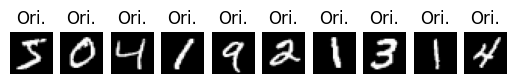

In [21]:
for i in range(10):
  plt.subplot(2,10,i+1)
  plt.imshow(X[i].reshape(28,28),cmap="gray")
  plt.title("Ori.")
  plt.axis("off")


Reconstruct image

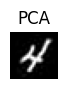

In [28]:
plt.subplot(2,10,i+11)
plt.imshow(
    X_reconstruct[i].reshape(28,28),
    cmap="gray",
    vmin=0,
    vmax=1

)
plt.title("PCA")
plt.axis("off")

plt.tight_layout()
plt.show()


Display compression information


In [26]:
print("Original feature: ",X.shape[1])
print("Reduced features: ",pca.n_components_)
print("Explained variance: ", np.sum(pca.explained_variance_ratio_))

Original feature:  784
Reduced features:  148
Explained variance:  0.9501308036338099


Calculate dimensionality reduction

In [29]:
reduction = (
    1-X_compressed.shape[1]/X.shape[1]
) * 100

In [30]:
print("Dimesionality Reduction: ",round(reduction,2),"%")

Dimesionality Reduction:  81.12 %
